<a href="https://colab.research.google.com/github/Ayaawasis-collab/ANALISIS-MULTIVARIAT/blob/main/UTS_ANMUL_WASIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from google.colab import files
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Library siap digunakan.")

Library siap digunakan.


In [2]:
uploaded = files.upload()
dataset = next(iter(uploaded))

df = pd.read_excel(dataset)
print("Ukuran dataset:", df.shape)
print("Nama kolom:", df.columns.tolist())
display(df.head())

Saving Dataset_MLR_Kalimantan_Tengah_2024.xlsx to Dataset_MLR_Kalimantan_Tengah_2024.xlsx
Ukuran dataset: (70, 7)
Nama kolom: ['No', 'Kabupaten_Kota', 'Tahun', 'LPE', 'IPM', 'Kemiskinan', 'TPT']


,No,Kabupaten_Kota,Tahun,LPE,IPM,Kemiskinan,TPT
0,1,Kotawaringin Barat,2020,0.9800,73.9500,3.5900,4.7600
1,2,Kotawaringin Timur,2020,-3.0600,73.1800,5.6200,5.2500
2,3,Kapuas,2020,-1.0400,71.1800,5.0400,4.9800
3,4,Barito Selatan,2020,-2.9000,72.7300,4.4500,4.2100
4,5,Barito Utara,2020,-2.2400,71.4400,5.1700,5.2900


In [3]:
# Kolom yang diperlukan untuk model ini
kolom_wajib = ["Kabupaten_Kota", "Tahun", "LPE", "IPM", "Kemiskinan", "TPT"]
kolom_hilang = [kolom for kolom in kolom_wajib if kolom not in df.columns]

if kolom_hilang:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {kolom_hilang}. "
        "Periksa nama kolom di file Excel."
    )

# Ambil kolom yang digunakan dan buat salinan
df = df[kolom_wajib].copy()

# Ubah variabel numerik menjadi tipe angka
kolom_numerik = ["Tahun", "LPE", "IPM", "Kemiskinan", "TPT"]
for kolom in kolom_numerik:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

df["Kabupaten_Kota"] = df["Kabupaten_Kota"].astype("string").str.strip()
df = df.replace([np.inf, -np.inf], np.nan)

print("Jumlah nilai kosong sebelum penanganan:")
display(df.isna().sum().to_frame("Jumlah_NA"))

# Hapus hanya baris yang tidak lengkap pada variabel analisis
df = df.dropna(subset=kolom_wajib).copy()

print("Jumlah observasi setelah pembersihan:", len(df))
print("Jumlah wilayah:", df["Kabupaten_Kota"].nunique())
print("Rentang tahun:", int(df["Tahun"].min()), "-", int(df["Tahun"].max()))
print("Duplikat kombinasi wilayah-tahun:",
      df.duplicated(subset=["Kabupaten_Kota", "Tahun"]).sum())

display(df.head())

Jumlah nilai kosong sebelum penanganan:


,Jumlah_NA
Kabupaten_Kota,0
Tahun,0
LPE,0
IPM,0
Kemiskinan,0
TPT,0


Jumlah observasi setelah pembersihan: 70
Jumlah wilayah: 14
Rentang tahun: 2020 - 2024
Duplikat kombinasi wilayah-tahun: 0


,Kabupaten_Kota,Tahun,LPE,IPM,Kemiskinan,TPT
0,Kotawaringin Barat,2020,0.9800,73.9500,3.5900,4.7600
1,Kotawaringin Timur,2020,-3.0600,73.1800,5.6200,5.2500
2,Kapuas,2020,-1.0400,71.1800,5.0400,4.9800
3,Barito Selatan,2020,-2.9000,72.7300,4.4500,4.2100
4,Barito Utara,2020,-2.2400,71.4400,5.1700,5.2900


In [4]:
variabel = ["LPE", "IPM", "Kemiskinan", "TPT"]

print("Statistik deskriptif:")
display(df[variabel].describe().T)

print("Rata-rata per variabel:")
display(df[variabel].mean().to_frame("Rata-rata"))

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
LPE,70.0000,3.5960,2.7816,-3.1800,2.7150,4.3500,5.6025,7.4100
IPM,70.0000,72.9873,2.9051,69.0400,71.2200,72.7200,73.9375,82.5300
Kemiskinan,70.0000,5.0459,1.1517,3.0900,4.0950,5.1900,5.7725,7.4300
TPT,70.0000,4.0696,1.0855,1.9600,3.1325,4.2300,4.9400,6.4600


Rata-rata per variabel:


,Rata-rata
LPE,3.5960
IPM,72.9873
Kemiskinan,5.0459
TPT,4.0696


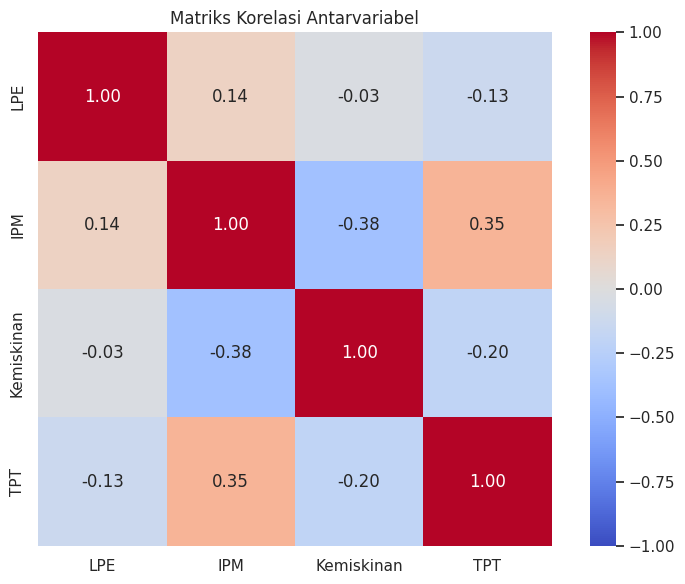

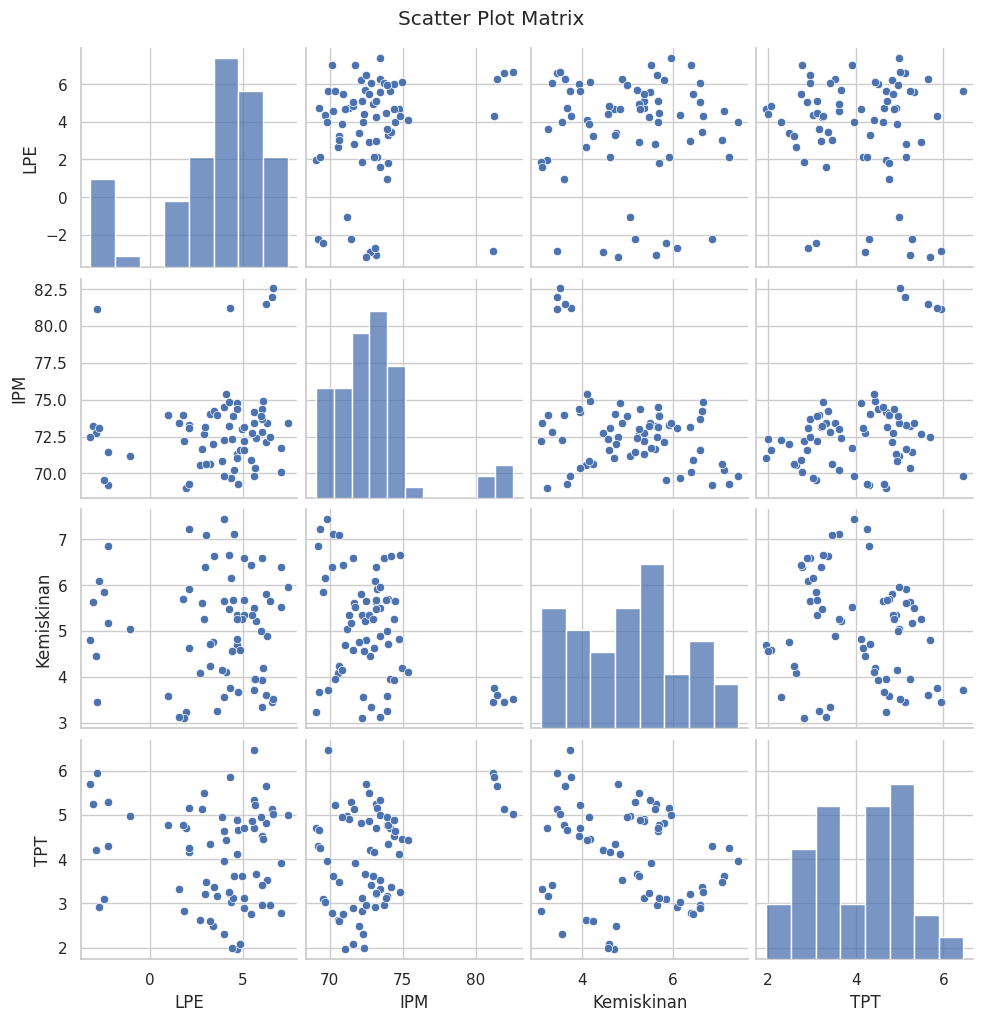

In [5]:
# Matriks korelasi
matriks_korelasi = df[variabel].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    matriks_korelasi, annot=True, cmap="coolwarm",
    vmin=-1, vmax=1, fmt=".2f", square=True
)
plt.title("Matriks Korelasi Antarvariabel")
plt.tight_layout()
plt.show()

# Scatter plot matrix
sns.pairplot(df[variabel], diag_kind="hist")
plt.suptitle("Scatter Plot Matrix", y=1.02)
plt.show()

In [6]:
# Variabel dependen (Y) dan variabel independen (X)
Y = df["LPE"]
X = df[["IPM", "Kemiskinan", "TPT"]]

# Tambahkan intersep/konstanta
X_const = sm.add_constant(X, has_constant="add")

# Estimasi Ordinary Least Squares (OLS)
model = sm.OLS(Y, X_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    LPE   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     1.262
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.295
Time:                        14:47:07   Log-Likelihood:                -168.48
No. Observations:                  70   AIC:                             345.0
Df Residuals:                      66   BIC:                             354.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -9.3329      9.860     -0.947      0.3

In [7]:
# Tabel koefisien, standard error, statistik t, p-value, dan CI 95%
ci = model.conf_int(alpha=0.05)
tabel_koef = pd.DataFrame({
    "Koefisien": model.params,
    "Std_Error": model.bse,
    "t_value": model.tvalues,
    "p_value": model.pvalues,
    "CI_95_Bawah": ci[0],
    "CI_95_Atas": ci[1]
})
display(tabel_koef.round(4))

# Cetak persamaan regresi dengan tanda koefisien yang benar
koef = model.params
persamaan = f"LPE = {koef['const']:.4f}"
for nama in ["IPM", "Kemiskinan", "TPT"]:
    tanda = "+" if koef[nama] >= 0 else "-"
    persamaan += f" {tanda} {abs(koef[nama]):.4f}({nama})"
print("\nPersamaan regresi:")
print(persamaan)

,Koefisien,Std_Error,t_value,p_value,CI_95_Bawah,CI_95_Atas
const,-9.3329,9.8603,-0.9465,0.3473,-29.0196,10.3538
IPM,0.2036,0.1300,1.5657,0.1222,-0.0560,0.4632
Kemiskinan,0.0288,0.3135,0.0918,0.9271,-0.5972,0.6548
TPT,-0.5103,0.3288,-1.5522,0.1254,-1.1667,0.1461



Persamaan regresi:
LPE = -9.3329 + 0.2036(IPM) + 0.0288(Kemiskinan) - 0.5103(TPT)


In [8]:
alpha = 0.05
f_stat = float(model.fvalue)
f_pvalue = float(model.f_pvalue)

print("Hipotesis:")
print("H0: beta IPM = beta Kemiskinan = beta TPT = 0")
print("H1: Minimal ada satu koefisien variabel bebas yang tidak sama dengan 0")
print(f"F-statistic = {f_stat:.4f}")
print(f"p-value     = {f_pvalue:.6g}")

if f_pvalue < alpha:
    print("Keputusan: Tolak H0 pada taraf signifikansi 5%.")
    print("Kesimpulan: variabel bebas secara bersama-sama signifikan secara statistik dalam model.")
else:
    print("Keputusan: Gagal menolak H0 pada taraf signifikansi 5%.")
    print("Kesimpulan: bukti belum cukup untuk menyatakan variabel bebas secara bersama-sama signifikan.")

Hipotesis:
H0: beta IPM = beta Kemiskinan = beta TPT = 0
H1: Minimal ada satu koefisien variabel bebas yang tidak sama dengan 0
F-statistic = 1.2620
p-value     = 0.294658
Keputusan: Gagal menolak H0 pada taraf signifikansi 5%.
Kesimpulan: bukti belum cukup untuk menyatakan variabel bebas secara bersama-sama signifikan.


In [9]:
print("H0 untuk setiap koefisien: beta_j = 0")
print("H1 untuk setiap koefisien: beta_j != 0")

tabel_uji_t = tabel_koef.loc[["IPM", "Kemiskinan", "TPT"],
                            ["Koefisien", "t_value", "p_value"]].copy()
tabel_uji_t["Keputusan_5%"] = np.where(
    tabel_uji_t["p_value"] < alpha,
    "Signifikan (tolak H0)",
    "Belum signifikan (gagal menolak H0)"
)
display(tabel_uji_t.round(4))

H0 untuk setiap koefisien: beta_j = 0
H1 untuk setiap koefisien: beta_j != 0


,Koefisien,t_value,p_value,Keputusan_5%
IPM,0.2036,1.5657,0.1222,Belum signifikan (gagal menolak H0)
Kemiskinan,0.0288,0.0918,0.9271,Belum signifikan (gagal menolak H0)
TPT,-0.5103,-1.5522,0.1254,Belum signifikan (gagal menolak H0)


In [10]:
n_obs = int(model.nobs)
k = int(len(model.params))  # termasuk konstanta
aic_value = model.aic
bic_value = model.bic

# AICc hanya terdefinisi jika n - k - 1 > 0
aicc_value = (
    aic_value + (2 * k * (k + 1)) / (n_obs - k - 1)
    if n_obs - k - 1 > 0 else np.nan
)

print(f"R-squared              : {model.rsquared:.4f}")
print(f"Adjusted R-squared     : {model.rsquared_adj:.4f}")
print(f"Residual Standard Error: {np.sqrt(model.mse_resid):.4f}")
print(f"AIC                    : {aic_value:.4f}")
print(f"BIC                    : {bic_value:.4f}")
print(f"AICc                   : {aicc_value:.4f}")

print(
    f"\nModel menjelaskan sekitar {model.rsquared * 100:.2f}% "
    "variasi LPE pada data yang digunakan untuk estimasi."
)
print("R-squared bukan bukti hubungan sebab-akibat dan bukan ukuran performa pada data baru.")

R-squared              : 0.0543
Adjusted R-squared     : 0.0113
Residual Standard Error: 2.7659
AIC                    : 344.9628
BIC                    : 353.9568
AICc                   : 345.5782

Model menjelaskan sekitar 5.43% variasi LPE pada data yang digunakan untuk estimasi.
R-squared bukan bukti hubungan sebab-akibat dan bukan ukuran performa pada data baru.


In [11]:
residual = model.resid
fitted = model.fittedvalues

shapiro_stat, shapiro_p = stats.shapiro(residual)
print(f"Shapiro-Wilk W = {shapiro_stat:.4f}")
print(f"p-value       = {shapiro_p:.4f}")

if shapiro_p > alpha:
    print("Gagal menolak H0: tidak ditemukan bukti kuat bahwa residual menyimpang dari normalitas.")
else:
    print("Tolak H0: residual menunjukkan penyimpangan dari normalitas.")

print("Catatan: uji normalitas sensitif terhadap ukuran sampel; periksa juga Q-Q plot.")

Shapiro-Wilk W = 0.8980
p-value       = 0.0000
Tolak H0: residual menunjukkan penyimpangan dari normalitas.
Catatan: uji normalitas sensitif terhadap ukuran sampel; periksa juga Q-Q plot.


In [ ]:
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(residual, X_const)
print(f"Breusch-Pagan LM statistic = {bp_lm:.4f}")
print(f"p-value (LM)               = {bp_lm_p:.4f}")
print(f"p-value (F)                = {bp_f_p:.4f}")

if bp_lm_p > alpha:
    print("Gagal menolak H0: belum ada bukti statistik heteroskedastisitas.")
else:
    print("Tolak H0: terdapat indikasi heteroskedastisitas.")

In [ ]:
dw = durbin_watson(residual)
print(f"Durbin-Watson = {dw:.4f}")
print("Nilai sekitar 2 sering diasosiasikan dengan tidak adanya autokorelasi orde pertama.")
print(
    "Peringatan: data ini berulang menurut kabupaten/kota dan tahun. "
    "Durbin-Watson pada urutan baris biasa tidak cukup untuk menyimpulkan "
    "independensi residual pada data panel."
)

In [12]:
X_vif = df[["IPM", "Kemiskinan", "TPT"]].astype(float)

tabel_vif = pd.DataFrame({
    "Variabel": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.to_numpy(), i)
        for i in range(X_vif.shape[1])
    ]
})
tabel_vif["Tolerance"] = 1 / tabel_vif["VIF"]
display(tabel_vif.round(4))

print("VIF tinggi dapat mengindikasikan multikolinearitas.")
print("Batas 5 atau 10 hanyalah pedoman praktis, bukan aturan mutlak.")

,Variabel,VIF,Tolerance
0,IPM,1.2872,0.7769
1,Kemiskinan,1.1762,0.8502
2,TPT,1.1487,0.8706


VIF tinggi dapat mengindikasikan multikolinearitas.
Batas 5 atau 10 hanyalah pedoman praktis, bukan aturan mutlak.


In [13]:
reset = linear_reset(model, power=2, use_f=True)
print(f"Ramsey RESET F = {float(reset.fvalue):.4f}")
print(f"p-value        = {float(reset.pvalue):.4f}")

if reset.pvalue > alpha:
    print("Gagal menolak H0: uji ini belum menemukan bukti kuat kesalahan spesifikasi.")
else:
    print("Tolak H0: ada indikasi spesifikasi model perlu ditinjau.")
print("RESET bukan bukti mutlak bahwa hubungan sudah linear atau model sudah benar.")

Ramsey RESET F = 0.7151
p-value        = 0.4009
Gagal menolak H0: uji ini belum menemukan bukti kuat kesalahan spesifikasi.
RESET bukan bukti mutlak bahwa hubungan sudah linear atau model sudah benar.


In [14]:
influence = OLSInfluence(model)
cooks_d = influence.cooks_distance[0]
leverage = influence.hat_matrix_diag
student_resid = influence.resid_studentized_external
dfbetas = influence.dfbetas

n = len(df)
p = len(model.params)
cook_threshold = 4 / n
leverage_threshold = 2 * p / n

diagnostik = df[["Kabupaten_Kota", "Tahun"]].copy()
diagnostik["Residual"] = residual.to_numpy()
diagnostik["Studentized_Residual"] = student_resid
diagnostik["Leverage"] = leverage
diagnostik["Cooks_Distance"] = cooks_d

print(f"Batas panduan Cook's Distance (4/n): {cook_threshold:.4f}")
print(f"Batas panduan leverage (2p/n):      {leverage_threshold:.4f}")
print("Jumlah |studentized residual| > 3:", int(np.sum(np.abs(student_resid) > 3)))
print("Jumlah Cook's Distance > 4/n:", int(np.sum(cooks_d > cook_threshold)))
print("Jumlah leverage > 2p/n:", int(np.sum(leverage > leverage_threshold)))

display(
    diagnostik.sort_values("Cooks_Distance", ascending=False).head(10).round(4)
)

print("Observasi yang terdeteksi perlu diperiksa tidak otomatis harus dihapus.")

Batas panduan Cook's Distance (4/n): 0.0571
Batas panduan leverage (2p/n):      0.1143
Jumlah |studentized residual| > 3: 0
Jumlah Cook's Distance > 4/n: 5
Jumlah leverage > 2p/n: 7


,Kabupaten_Kota,Tahun,Residual,Studentized_Residual,Leverage,Cooks_Distance
13,Palangka Raya,2020,-7.1062,-2.9239,0.1396,0.3111
33,Sukamara,2022,3.9187,1.5750,0.1726,0.1265
11,Barito Timur,2020,-6.9687,-2.6989,0.0455,0.0793
8,Katingan,2020,-5.8323,-2.2343,0.0554,0.0690
7,Seruyan,2020,-4.9933,-1.9067,0.0677,0.0635
1,Kotawaringin Timur,2020,-6.1094,-2.3279,0.0394,0.0521
12,Murung Raya,2020,-5.8621,-2.2261,0.0392,0.0477
4,Barito Utara,2020,-4.9018,-1.8482,0.0469,0.0405
47,Sukamara,2023,3.2044,1.2133,0.0818,0.0325
3,Barito Selatan,2020,-6.3548,-2.4031,0.0198,0.0271


Observasi yang terdeteksi perlu diperiksa tidak otomatis harus dihapus.


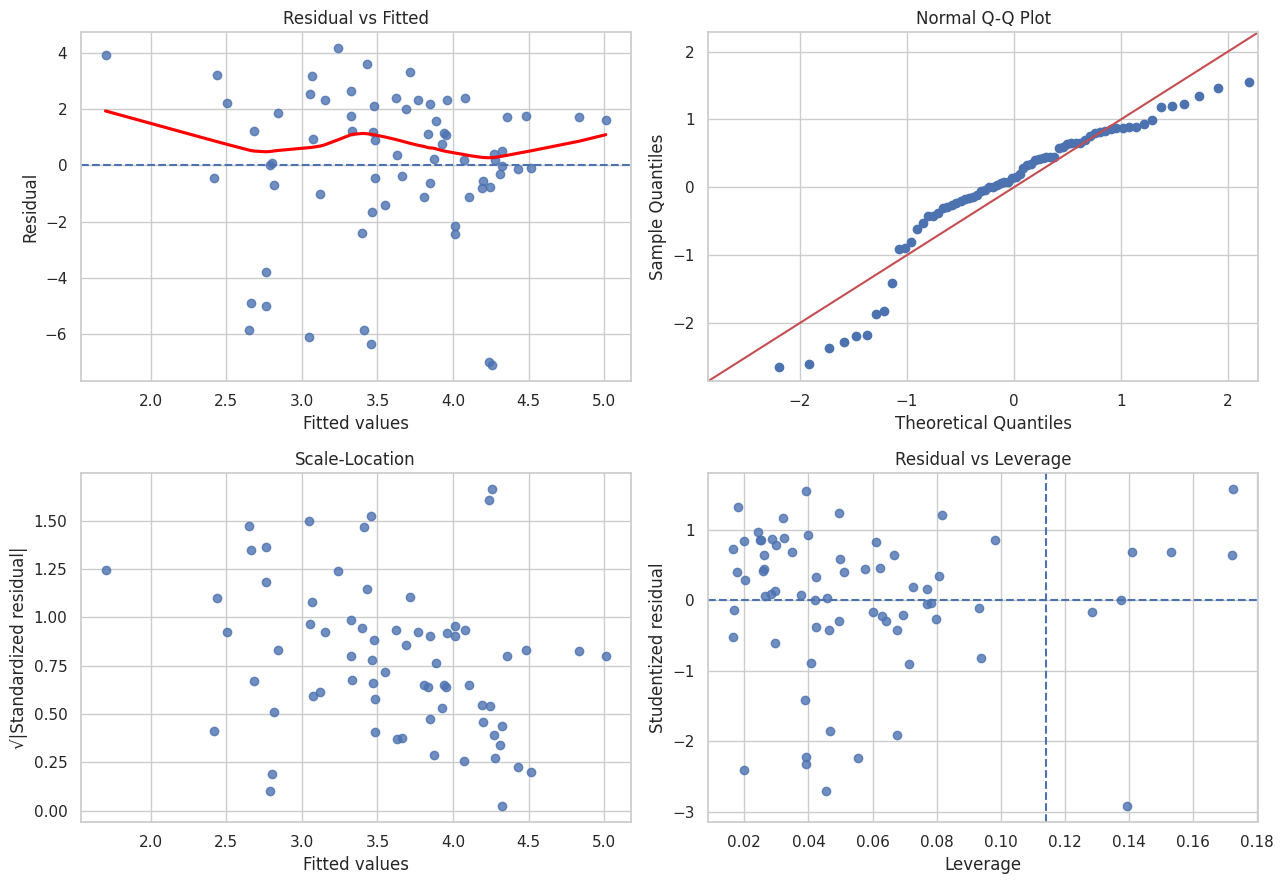

In [15]:
# Empat grafik diagnostik
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Residual vs fitted
axes[0, 0].scatter(fitted, residual, alpha=0.8)
axes[0, 0].axhline(0, linestyle="--")
sns.regplot(x=fitted, y=residual, lowess=True, scatter=False,
            ax=axes[0, 0], line_kws={"color": "red"})
axes[0, 0].set_title("Residual vs Fitted")
axes[0, 0].set_xlabel("Fitted values")
axes[0, 0].set_ylabel("Residual")

# 2. Q-Q plot
sm.qqplot(residual, line="45", fit=True, ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q Plot")

# 3. Scale-location
std_resid = influence.resid_studentized_internal
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_resid)), alpha=0.8)
axes[1, 0].set_title("Scale-Location")
axes[1, 0].set_xlabel("Fitted values")
axes[1, 0].set_ylabel("√|Standardized residual|")

# 4. Residual vs leverage
axes[1, 1].scatter(leverage, student_resid, alpha=0.8)
axes[1, 1].axhline(0, linestyle="--")
axes[1, 1].axvline(leverage_threshold, linestyle="--")
axes[1, 1].set_title("Residual vs Leverage")
axes[1, 1].set_xlabel("Leverage")
axes[1, 1].set_ylabel("Studentized residual")

plt.tight_layout()
plt.show()

In [16]:
# Fungsi pemilihan model berbasis AIC
def fit_formula(predictors):
    if len(predictors) == 0:
        exog = pd.DataFrame({"const": np.ones(len(df))}, index=df.index)
    else:
        exog = sm.add_constant(df[predictors], has_constant="add")
    return sm.OLS(Y, exog).fit()

def forward_selection(candidates):
    selected = []
    current_model = fit_formula(selected)
    improved = True

    while improved:
        improved = False
        remaining = [v for v in candidates if v not in selected]
        options = [(fit_formula(selected + [v]).aic, v)
                   for v in remaining]
        if options:
            best_aic, best_var = min(options)
            if best_aic < current_model.aic - 1e-8:
                selected.append(best_var)
                current_model = fit_formula(selected)
                improved = True
    return selected, current_model

def backward_selection(candidates):
    selected = list(candidates)
    current_model = fit_formula(selected)
    improved = True

    while improved and selected:
        improved = False
        options = [(fit_formula([v for v in selected if v != drop_var]).aic,
                    drop_var) for drop_var in selected]
        best_aic, drop_var = min(options)
        if best_aic < current_model.aic - 1e-8:
            selected.remove(drop_var)
            current_model = fit_formula(selected)
            improved = True
    return selected, current_model

def stepwise_selection(candidates):
    selected = []
    current_model = fit_formula(selected)
    changed = True

    while changed:
        changed = False
        remaining = [v for v in candidates if v not in selected]

        # Coba menambahkan satu variabel
        add_options = [(fit_formula(selected + [v]).aic, v)
                       for v in remaining]
        if add_options:
            best_aic, best_var = min(add_options)
            if best_aic < current_model.aic - 1e-8:
                selected.append(best_var)
                current_model = fit_formula(selected)
                changed = True

        # Coba menghapus variabel jika AIC membaik
        if selected:
            drop_options = [
                (fit_formula([v for v in selected if v != drop_var]).aic,
                 drop_var)
                for drop_var in selected
            ]
            best_aic, drop_var = min(drop_options)
            if best_aic < current_model.aic - 1e-8:
                selected.remove(drop_var)
                current_model = fit_formula(selected)
                changed = True

    return selected, current_model

kandidat = ["IPM", "Kemiskinan", "TPT"]

vars_forward, model_forward = forward_selection(kandidat)
vars_backward, model_backward = backward_selection(kandidat)
vars_stepwise, model_stepwise = stepwise_selection(kandidat)

def hitung_aicc(m):
    n_obs = int(m.nobs)
    k = len(m.params)
    if n_obs - k - 1 <= 0:
        return np.nan
    return m.aic + (2 * k * (k + 1)) / (n_obs - k - 1)

perbandingan = pd.DataFrame([
    {
        "Model": "Model Awal",
        "Variabel": ", ".join(kandidat),
        "AIC": model.aic,
        "BIC": model.bic,
        "AICc": hitung_aicc(model),
        "R_squared": model.rsquared
    },
    {
        "Model": "Forward",
        "Variabel": ", ".join(vars_forward) if vars_forward else "(intersep saja)",
        "AIC": model_forward.aic,
        "BIC": model_forward.bic,
        "AICc": hitung_aicc(model_forward),
        "R_squared": model_forward.rsquared
    },
    {
        "Model": "Backward",
        "Variabel": ", ".join(vars_backward) if vars_backward else "(intersep saja)",
        "AIC": model_backward.aic,
        "BIC": model_backward.bic,
        "AICc": hitung_aicc(model_backward),
        "R_squared": model_backward.rsquared
    },
    {
        "Model": "Stepwise",
        "Variabel": ", ".join(vars_stepwise) if vars_stepwise else "(intersep saja)",
        "AIC": model_stepwise.aic,
        "BIC": model_stepwise.bic,
        "AICc": hitung_aicc(model_stepwise),
        "R_squared": model_stepwise.rsquared
    }
])

display(perbandingan.round(4))
print("Variabel model forward :", vars_forward)
print("Variabel model backward:", vars_backward)
print("Variabel model stepwise:", vars_stepwise)
print("\nRingkasan model stepwise:")
print(model_stepwise.summary())

,Model,Variabel,AIC,BIC,AICc,R_squared
0,Model Awal,"IPM, Kemiskinan, TPT",344.9628,353.9568,345.5782,0.0543
1,Forward,(intersep saja),342.8673,345.1158,342.9261,-0.0000
2,Backward,"IPM, TPT",342.9718,349.7172,343.3354,0.0541
3,Stepwise,(intersep saja),342.8673,345.1158,342.9261,-0.0000


Variabel model forward : []
Variabel model backward: ['IPM', 'TPT']
Variabel model stepwise: []

Ringkasan model stepwise:
                            OLS Regression Results                            
Dep. Variable:                    LPE   R-squared:                      -0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                       nan
Date:                Sun, 25 Oct 2026   Prob (F-statistic):                nan
Time:                        14:48:21   Log-Likelihood:                -170.43
No. Observations:                  70   AIC:                             342.9
Df Residuals:                      69   BIC:                             345.1
Df Model:                           0                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------

In [17]:
hasil = df[["Kabupaten_Kota", "Tahun", "LPE"]].copy()
hasil = hasil.rename(columns={"LPE": "LPE_Aktual"})
hasil["LPE_Prediksi"] = model.predict(X_const)
hasil["Residual"] = hasil["LPE_Aktual"] - hasil["LPE_Prediksi"]

display(hasil.head(15))

# Ekspor tabel hasil dan tabel koefisien ke satu file Excel
with pd.ExcelWriter("Hasil_Analisis_MLR_Kalimantan_Tengah.xlsx") as writer:
    hasil.to_excel(writer, sheet_name="Aktual_Prediksi", index=False)
    tabel_koef.to_excel(writer, sheet_name="Koefisien")
    tabel_vif.to_excel(writer, sheet_name="VIF", index=False)
    perbandingan.to_excel(writer, sheet_name="Perbandingan_Model", index=False)

print("File Excel berhasil dibuat.")
files.download("Hasil_Analisis_MLR_Kalimantan_Tengah.xlsx")

,Kabupaten_Kota,Tahun,LPE_Aktual,LPE_Prediksi,Residual
0,Kotawaringin Barat,2020,0.9800,3.3978,-2.4178
1,Kotawaringin Timur,2020,-3.0600,3.0494,-6.1094
2,Kapuas,2020,-1.0400,2.7633,-3.8033
3,Barito Selatan,2020,-2.9000,3.4548,-6.3548
4,Barito Utara,2020,-2.2400,2.6618,-4.9018
5,Sukamara,2020,1.9800,2.4183,-0.4383
6,Lamandau,2020,1.8500,4.0140,-2.1640
7,Seruyan,2020,-2.2300,2.7633,-4.9933
8,Katingan,2020,-3.1800,2.6523,-5.8323
9,Pulang Pisau,2020,2.6800,3.8109,-1.1309


File Excel berhasil dibuat.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# Hitung ulang variabel diagnostik untuk mencegah NameError jika sel sebelumnya belum dijalankan
try:
    shapiro_p_val = shapiro_p
except NameError:
    _, shapiro_p_val = stats.shapiro(model.resid)

try:
    bp_lm_p_val = bp_lm_p
except NameError:
    _, bp_lm_p_val, _, _ = het_breuschpagan(model.resid, X_const)

try:
    dw_val = dw
except NameError:
    dw_val = durbin_watson(model.resid)

try:
    reset_p_val = float(reset.pvalue)
except NameError:
    reset_p_val = float(linear_reset(model, power=2, use_f=True).pvalue)

print("=" * 65)
print("RINGKASAN ANALISIS REGRESI LINIER BERGANDA")
print("=" * 65)

print("\nVariabel dependen: LPE")
print("Variabel independen: IPM, Kemiskinan, TPT")
print(f"Jumlah observasi: {int(model.nobs)}")
print(f"R-squared: {model.rsquared:.4f}")
print(f"Adjusted R-squared: {model.rsquared_adj:.4f}")
print(f"F-statistic: {model.fvalue:.4f}")
print(f"p-value uji F: {model.f_pvalue:.6g}")

print("\nP-value uji t:")
for var in ["IPM", "Kemiskinan", "TPT"]:
    print(f"- {var}: {model.pvalues[var]:.6g}")

print("\nDiagnostik:")
print(f"- Shapiro-Wilk p-value: {shapiro_p_val:.4f}")
print(f"- Breusch-Pagan p-value: {bp_lm_p_val:.4f}")
print(f"- Durbin-Watson: {dw_val:.4f}")
print(f"- VIF maksimum: {tabel_vif['VIF'].max():.4f}")
print(f"- Ramsey RESET p-value: {reset_p_val:.4f}")

print("\nCatatan interpretasi:")
print("1. Hasil menunjukkan asosiasi statistik, bukan otomatis sebab-akibat.")
print("2. Periksa asumsi dan observasi berpengaruh sebelum membuat kesimpulan.")
print("3. Data wilayah-tahun berstruktur panel; pertimbangkan model panel/SE terklaster.")
print("4. Dataset ini memakai LPE sebagai Y, bukan nilai PDRB langsung.")
print("=" * 65)

RINGKASAN ANALISIS REGRESI LINIER BERGANDA

Variabel dependen: LPE
Variabel independen: IPM, Kemiskinan, TPT
Jumlah observasi: 70
R-squared: 0.0543
Adjusted R-squared: 0.0113
F-statistic: 1.2620
p-value uji F: 0.294658

P-value uji t:
- IPM: 0.122194
- Kemiskinan: 0.927117
- TPT: 0.125404

Diagnostik:
- Shapiro-Wilk p-value: 0.0000
- Breusch-Pagan p-value: 0.1707
- Durbin-Watson: 0.8184
- VIF maksimum: 1.2872
- Ramsey RESET p-value: 0.4009

Catatan interpretasi:
1. Hasil menunjukkan asosiasi statistik, bukan otomatis sebab-akibat.
2. Periksa asumsi dan observasi berpengaruh sebelum membuat kesimpulan.
3. Data wilayah-tahun berstruktur panel; pertimbangkan model panel/SE terklaster.
4. Dataset ini memakai LPE sebagai Y, bukan nilai PDRB langsung.
